# Random Forest Regressor

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance

In [2]:
df = pd.read_csv("../data/final_dataset.csv")

In [3]:
# Features used to predict price
numeric = ["year", "mileage_km"]

categorical = [
    "make",
    "model",
    "body_style",
    "fuel_type",
    "regional_specs"
]

features = numeric + categorical

X = df[features].copy()
y = df["price_aed"]

# Handle missing category values
X[categorical] = X[categorical].fillna("Unknown")

# 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [4]:
# Convert text categories into numbers
preprocessor = ColumnTransformer(
    [
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical)
    ],
    remainder="passthrough"
)

# Set aside some training data for validation
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=42
)

best_mae = float("inf")
best_params = {}

# Try 6 combinations
for depth in [None, 20]:
    for leaf in [1, 3, 5]:

        model = Pipeline([
            ("preprocessing", preprocessor),
            ("random_forest", RandomForestRegressor(
                n_estimators=150,
                max_depth=depth,
                min_samples_leaf=leaf,
                random_state=42,
                n_jobs=-1
            ))
        ])

        model.fit(X_fit, y_fit)

        predictions_val = model.predict(X_val)
        mae = mean_absolute_error(y_val, predictions_val)

        print(f"Depth: {depth}, Leaf: {leaf}, MAE: {mae:,.0f}")

        if mae < best_mae:
            best_mae = mae
            best_params = {
                "max_depth": depth,
                "min_samples_leaf": leaf
            }

print("\nBest parameters:", best_params)

# Train the final model using all training data
model = Pipeline([
    ("preprocessing", preprocessor),
    ("random_forest", RandomForestRegressor(
        n_estimators=150,
        **best_params,
        random_state=42,
        n_jobs=-1
    ))
])

model.fit(X_train, y_train)

Depth: None, Leaf: 1, MAE: 20,356
Depth: None, Leaf: 3, MAE: 28,282
Depth: None, Leaf: 5, MAE: 32,380
Depth: 20, Leaf: 1, MAE: 27,634
Depth: 20, Leaf: 3, MAE: 29,801
Depth: 20, Leaf: 5, MAE: 32,586

Best parameters: {'max_depth': None, 'min_samples_leaf': 1}


/Users/m.mohammed/ds_env/lib/python3.11/site-packages/sklearn/compose/_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


Pipeline(steps=[('preprocessing',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('categorical',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['make', 'model',
                                                   'body_style', 'fuel_type',
                                                   'regional_specs'])])),
                ('random_forest',
                 RandomForestRegressor(n_estimators=150, n_jobs=-1,
                                       random_state=42))])

In [5]:
predictions = model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
r2 = r2_score(y_test, predictions)

print(f"Mean Absolute Error: AED {mae:,.0f}")
print(f"R² Score: {r2:.3f}")

Mean Absolute Error: AED 19,169
R² Score: 0.806


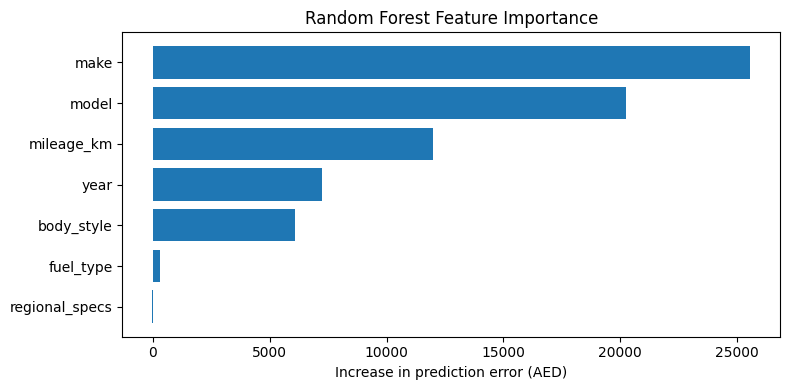

In [6]:
importance = permutation_importance(
    model,
    X_test,
    y_test,
    scoring="neg_mean_absolute_error",
    n_repeats=5,
    random_state=42
)

importance_df = pd.DataFrame({
    "feature": X_test.columns,
    "importance": importance.importances_mean
})

importance_df = importance_df.sort_values("importance")

plt.figure(figsize=(8, 4))
plt.barh(importance_df["feature"], importance_df["importance"])
plt.xlabel("Increase in prediction error (AED)")
plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.show()

In [7]:
results = pd.DataFrame({
    "Actual Price": y_test,
    "Predicted Price": predictions
})

results["Error"] = abs(
    results["Actual Price"] - results["Predicted Price"]
)

results["Price Range"] = pd.cut(
    results["Actual Price"],
    bins=[0, 50000, 100000, 200000, float("inf")],
    labels=["Under 50k", "50–100k", "100–200k", "200k+"]
)

print(results.groupby("Price Range", observed=True)["Error"].agg(
    ["count", "mean", "median"]
).round(0))

             count     mean   median
Price Range                         
Under 50k      119   9795.0   6382.0
50–100k        127  12244.0   9634.0
100–200k       127  20619.0  15227.0
200k+           40  64442.0  44278.0
